# 팀 프로젝트 셀

In [1]:
# ===== 팀 프로젝트 시작 셀 =====
import os, sys
from google.colab import userdata

TOKEN = userdata.get('GITHUB_TOKEN')
NAME = "Daun"
REPO_URL = "github.com/DA15-Lab/team3-ping-analytics.git"
PROJECT_DIR = "/content/team3-ping-analytics"

if not os.path.exists(PROJECT_DIR):
    !git clone -q https://{TOKEN}@{REPO_URL}
    %cd {PROJECT_DIR}
else:
    %cd {PROJECT_DIR}
    !git pull -q

!git config user.email "{NAME}@example.com"
!git config user.name "{NAME}"

!pip install -q -r requirements.txt

sys.path.append("/content/team3-ping-analytics/src")
from preprocess import *

print(module_test())
print("✅ 준비 완료")

In [ ]:
# ===== 작업 저장 셀 =====
NAME = "Daun"
PROJECT_DIR = "/content/team3-ping-analytics"

%cd {PROJECT_DIR}
!git config pull.rebase false

from google.colab import _message
import json

with open(f'notebooks/{NAME}_analysis.ipynb', 'w') as f:
    json.dump(_message.blocking_request('get_ipynb', timeout_sec=30)['ipynb'], f)

!pip freeze | grep -v "google-colab" > requirements.txt

!git add .
!git commit -m "paymenthistory, userquestionrecord 전처리"
!git pull
!git push

/content/team3-ping-analytics


# 분석 시작

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly as px

import os
import ast

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
# 지수 표기법 대신 소수점 2자리까지 표기
pd.set_option('display.float_format', lambda x: '%.2f' % x)

# 테이블 출력 시 컬럼 모두 나오게 하기
pd.set_option('display.max_columns', 100)

# 시각화 지수 표기법 사용하지 않기
plt.rcParams['axes.formatter.useoffset'] = False
plt.rcParams['axes.formatter.limits'] = (-10, 10)

# 시각화 한글 폰트 출력
import matplotlib.font_manager as fm
import platform
import subprocess

system_name = platform.system()

if system_name == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif system_name == 'Darwin':
    plt.rc('font', family='AppleGothic')
else:  # Linux (Colab)
    font_path = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
    fm.fontManager.addfont(font_path)  # 캐시 강제 등록
    plt.rc('font', family='NanumGothic')

plt.rcParams['axes.unicode_minus'] = False

# 함수 정의

In [ ]:
# 필요하다면 기재

# 전처리

## accounts_paymenthistory

In [63]:
def open_csv(table_name):
  folder_path = '/content/drive/MyDrive/코드잇 3팀 고급 프로젝트/00_원본 csv'
  file_path = os.path.join(folder_path, f'{table_name}.csv')
  return pd.read_csv(file_path)

df = open_csv('accounts_paymenthistory')
df.head()

,id,productId,phone_type,created_at,user_id
0,6,heart.777,A,2023-05-13 21:28:34,1211127
1,7,heart.777,A,2023-05-13 21:29:39,1151343
2,8,heart.777,A,2023-05-13 21:31:33,1002147
3,9,heart.777,A,2023-05-13 21:31:39,1095040
4,11,heart.777,A,2023-05-13 21:34:32,1164081


In [6]:
# 데이터 타입 확인
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 95140 entries, 0 to 95139
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id          95140 non-null  int64 
 1   productId   95140 non-null  object
 2   phone_type  95140 non-null  object
 3   created_at  95140 non-null  object
 4   user_id     95140 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 3.6+ MB


In [7]:
# created_at: object -> datetime
df['created_at'] = pd.to_datetime(df['created_at'])

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 95140 entries, 0 to 95139
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   id          95140 non-null  int64         
 1   productId   95140 non-null  object        
 2   phone_type  95140 non-null  object        
 3   created_at  95140 non-null  datetime64[ns]
 4   user_id     95140 non-null  int64         
dtypes: datetime64[ns](1), int64(2), object(2)
memory usage: 3.6+ MB


In [8]:
# 중복값 및 결측값 확인

def check_dup_and_na(df, id):
  print(f'행 중복 수: {df.duplicated().sum()}')
  print(f'id 중복 수: {df[id].duplicated().sum()}')
  print('')
  print('--- 컬럼별 결측 수 ---')
  display(df.isna().sum())


check_dup_and_na(df, 'id')

행 중복 수: 0
id 중복 수: 0

--- 컬럼별 결측 수 ---


,0
id,0
productId,0
phone_type,0
created_at,0
user_id,0


In [9]:
# id를 제외한 행의 중복값 재확인
df.drop(columns='id').duplicated().sum()

# 전체 행 중 비율
print(f'전체 행 중 비율: {len(df.drop(columns='id').duplicated().sum()) / len(df)*100}%')

np.int64(531)

> **중복값 처리**
* accounts_paymenthistory 테이블에서 id를 제외한 컬럼에서 중복값 **총 531행**

* 중복·중복아님 결정을 위해 다른 테이블과 교차 확인
  * `accounts_pointhistory`: 무료 포인트만 반영되는 듯함. 구매한 heart는 반영 안 됨
  * `accounts_failpaymenthistory`: 테이블에서 결제 실패 기록도 살펴봤지만, paymenthistory에서 중복된 행이 결제 실패 기록에는 없음
-> 중복값이라고 판별할만한 근거를 찾지 못함

* 가설
  * 한 번 구매할 때 한 상품 여러 개를 구매할 수 있다. -> 보존
  * 단순 기록 오류다 -> 삭제

* 결론
와이어프레임에서는 한 번 구매 시 한 상품 여러개를 구매할 수 있다는 표기가 없고, 중복 행의 수도 전체의 0.05% 수준으로 낮아 삭제 처리

In [10]:
df_clean = df.drop_duplicates(subset=df.columns.difference(['id']), keep='first')

print(f'삭제 전 행 수: {len(df)}')
print(f'삭제 후 행 수: {len(df_clean)}')
print(f'삭제된 행 수: {len(df) - len(df_clean)}')

# 제대로 지워졌는지 재확인
df_clean.drop(columns='id').duplicated().sum()

삭제 전 행 수: 95140
삭제 후 행 수: 94609
삭제된 행 수: 531


np.int64(0)

In [11]:
# 이상값 확인

def check_minmax(df, col):
  print(f'--- {col} minmax ---')
  print(f'MIN: {df[col].min()}')
  print(f'MAX: {df[col].max()}')
  print(f'행 수: {len(df)}')

def check_unique(df, col):
  print(f'--- {col} unique ---')
  print(df[col].unique())


minmax_cols = ['id', 'created_at', 'user_id']
for col in minmax_cols:
  check_minmax(df_clean, col)
  print('')

unique_cols = ['productId', 'phone_type']
for col in unique_cols:
  check_unique(df_clean, col)
  print('')

--- id minmax ---
MIN: 6
MAX: 98077
행 수: 94609

--- created_at minmax ---
MIN: 2023-05-13 21:28:34
MAX: 2024-05-08 14:12:45
행 수: 94609

--- user_id minmax ---
MIN: 833041
MAX: 1583632
행 수: 94609

--- productId unique ---
['heart.777' 'heart.200' 'heart.4000' 'heart.1000']

--- phone_type unique ---
['A' 'I']



`accounts_paymenthistory`의 id는 행 생성 시 순차적으로 숫자를 배정하는 것으로 보인다.  
테이블의 행 수보다 id의 최댓값이 큰데, id가 6부터 시작하는 등, 일부 데이터는 삭제된 것으로 보인다.  
따라서, 행 수보다 큰 id값은 이상치가 아니라고 판단하여 삭제하지 않도록 하겠다.

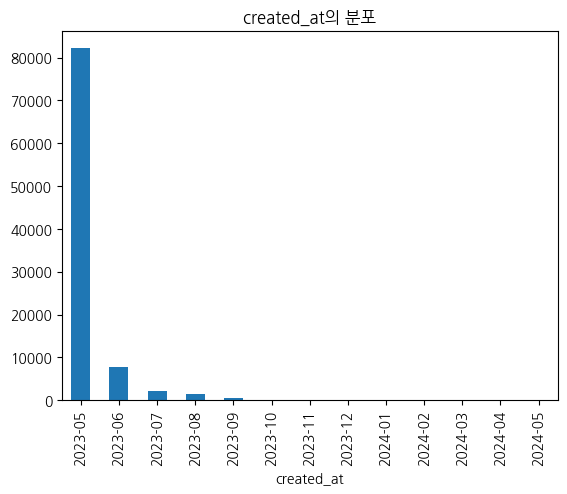

In [12]:
df_clean['created_at'].dt.to_period('M').value_counts().sort_index().plot(kind='bar')
plt.title('created_at의 분포')
plt.show()

In [65]:
# 유저 테이블 accounts_user에 속하지 않은 user_id 찾기
# 속하지 않은 user_id는 이상값 처리

account_user = open_csv('accounts_user')
account_user.head()

,id,is_superuser,is_staff,gender,point,friend_id_list,is_push_on,created_at,block_user_id_list,hide_user_id_list,ban_status,report_count,alarm_count,pending_chat,pending_votes,group_id
0,831956,1,1,NaN,600,"[1292473, 913158, 1488461, 1064695, 1043565, 1...",0,2023-03-29 03:44:14.047130,[],[],N,0,0,0,0,NaN
1,831962,0,0,F,2248,"[833025, 832642, 982531, 879496, 838541, 83752...",1,2023-03-29 05:18:56.162368,[],[],N,253,40878,5499,110,12.00
2,832151,0,0,M,1519,"[838785, 982531, 882567, 879496, 838541, 83649...",0,2023-03-29 12:56:34.989468,[],[],N,0,37,0,47,1.00
3,832340,0,0,F,57,"[841345, 982531, 838785, 963714, 882567, 83252...",1,2023-03-29 12:56:35.020790,[],[],N,0,19,0,21,1.00
4,832520,0,0,M,1039,"[874050, 849763, 874212, 844297, 838541, 84004...",0,2023-03-29 12:56:35.049311,[],[],N,0,29,0,15,12.00


In [39]:
# account_user의 user_id에 속하지 않은 user_id 추출
def check_valid_user_id(df, col):
  # account_user의 user_id 추출
  user_ids = account_user['id']

  cond = df[col].isin(user_ids)
  print(f'account_user의 user_id에 속하지 않은 {col} 수: {len(df[~cond])}')
  print('')
  display(df[~cond])

check_valid_user_id(df_clean, 'user_id')

account_user의 user_id에 속하지 않은 user_id 수: 0



,id,productId,phone_type,created_at,user_id


In [315]:
# 공유 드라이브에 저장

def save_to_drive(df, table_name):
  df_clean.to_csv(f'/content/drive/MyDrive/코드잇 3팀 고급 프로젝트/01_전처리 완료된 csv/{table_name}.csv',
                  index=False,
                  encoding='utf-8-sig')
  print('✅ 저장 완료!')

save_to_drive(df_clean, 'accounts_paymenthistory')

✅ 저장 완료!


## accounts_userquestionrecord

In [319]:
df = open_csv('accounts_userquestionrecord')
df.head()

,id,status,created_at,chosen_user_id,question_id,user_id,question_piece_id,has_read,answer_status,answer_updated_at,report_count,opened_times
0,771777,C,2023-04-28 12:27:49,849469,252,849436,998458,0,N,2023-04-28 12:27:49,0,0
1,771800,C,2023-04-28 12:28:02,849446,244,849436,998459,0,N,2023-04-28 12:28:02,0,0
2,771812,C,2023-04-28 12:28:09,849454,183,849436,998460,1,N,2023-04-28 12:28:09,0,0
3,771828,C,2023-04-28 12:28:16,847375,101,849436,998461,0,N,2023-04-28 12:28:16,0,0
4,771851,C,2023-04-28 12:28:26,849477,209,849436,998462,1,N,2023-04-28 12:28:26,0,0


In [320]:
# 데이터 타입 확인
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1217558 entries, 0 to 1217557
Data columns (total 12 columns):
 #   Column             Non-Null Count    Dtype 
---  ------             --------------    ----- 
 0   id                 1217558 non-null  int64 
 1   status             1217558 non-null  object
 2   created_at         1217558 non-null  object
 3   chosen_user_id     1217558 non-null  int64 
 4   question_id        1217558 non-null  int64 
 5   user_id            1217558 non-null  int64 
 6   question_piece_id  1217558 non-null  int64 
 7   has_read           1217558 non-null  int64 
 8   answer_status      1217558 non-null  object
 9   answer_updated_at  1217558 non-null  object
 10  report_count       1217558 non-null  int64 
 11  opened_times       1217558 non-null  int64 
dtypes: int64(8), object(4)
memory usage: 111.5+ MB


In [321]:
# 데이터타입 변경
# created_at: object -> datetime
# answer_updated_at: object -> datetime

df['created_at'] = pd.to_datetime(df['created_at'])
df['answer_updated_at'] = pd.to_datetime(df['answer_updated_at'])

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1217558 entries, 0 to 1217557
Data columns (total 12 columns):
 #   Column             Non-Null Count    Dtype         
---  ------             --------------    -----         
 0   id                 1217558 non-null  int64         
 1   status             1217558 non-null  object        
 2   created_at         1217558 non-null  datetime64[ns]
 3   chosen_user_id     1217558 non-null  int64         
 4   question_id        1217558 non-null  int64         
 5   user_id            1217558 non-null  int64         
 6   question_piece_id  1217558 non-null  int64         
 7   has_read           1217558 non-null  int64         
 8   answer_status      1217558 non-null  object        
 9   answer_updated_at  1217558 non-null  datetime64[ns]
 10  report_count       1217558 non-null  int64         
 11  opened_times       1217558 non-null  int64         
dtypes: datetime64[ns](2), int64(8), object(2)
memory usage: 111.5+ MB


In [322]:
# 중복값 및 결측값 확인

check_dup_and_na(df, 'id')

행 중복 수: 0
id 중복 수: 0

--- 컬럼별 결측 수 ---


,0
id,0
status,0
created_at,0
chosen_user_id,0
question_id,0
user_id,0
question_piece_id,0
has_read,0
answer_status,0
answer_updated_at,0


In [323]:
# id를 제외한 행의 중복값 재확인
df.drop(columns='id').duplicated().sum()

np.int64(0)

In [324]:
# 이상값 확인

minmax_cols = ['id', 'created_at', 'chosen_user_id', 'question_id', 'user_id',
               'question_piece_id', 'answer_updated_at', 'report_count', 'opened_times']

for col in minmax_cols:
  check_minmax(df, col)
  print('')

unique_cols = ['status', 'has_read', 'answer_status']
for col in unique_cols:
  check_unique(df, col)
  print('')

--- id minmax ---
MIN: 771777
MAX: 161666464
행 수: 1217558

--- created_at minmax ---
MIN: 2023-04-28 12:27:49
MAX: 2024-05-08 01:36:18
행 수: 1217558

--- chosen_user_id minmax ---
MIN: 833112
MAX: 1579422
행 수: 1217558

--- question_id minmax ---
MIN: 99
MAX: 5133
행 수: 1217558

--- user_id minmax ---
MIN: 838023
MAX: 1583358
행 수: 1217558

--- question_piece_id minmax ---
MIN: 998458
MAX: 208351468
행 수: 1217558

--- answer_updated_at minmax ---
MIN: 2023-04-28 12:27:49
MAX: 2024-05-08 01:36:18
행 수: 1217558

--- report_count minmax ---
MIN: 0
MAX: 14
행 수: 1217558

--- opened_times minmax ---
MIN: 0
MAX: 3
행 수: 1217558

--- status unique ---
['C' 'I' 'B']

--- has_read unique ---
[0 1]

--- answer_status unique ---
['N' 'P' 'A']



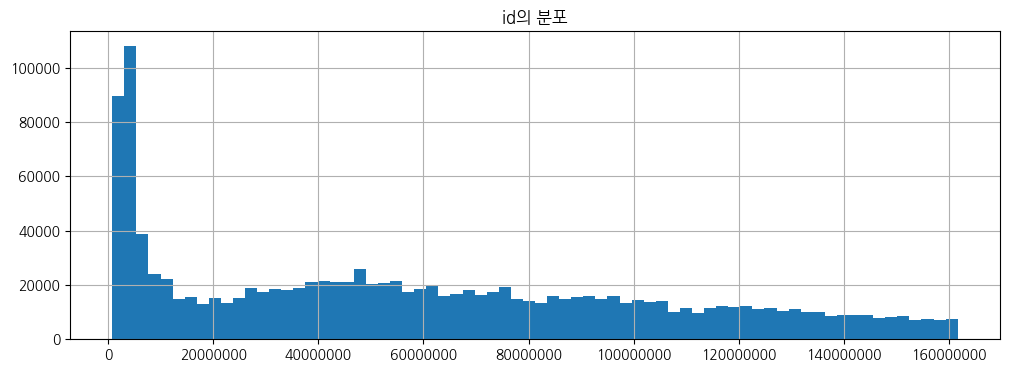

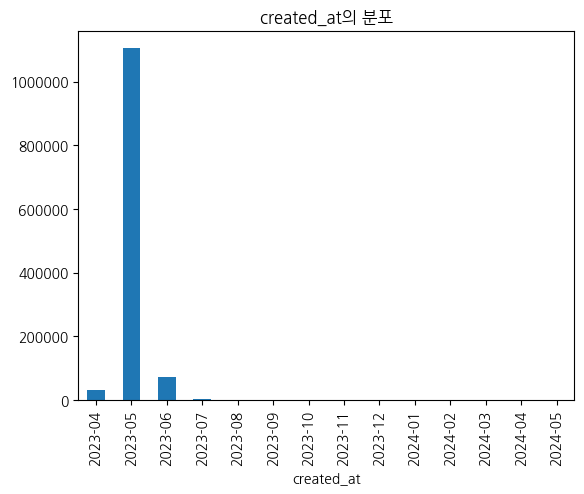

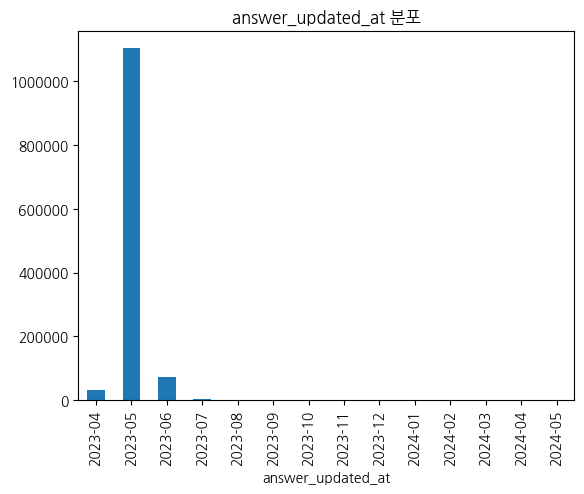

In [325]:
# id, created_at, answer_updated_at의 데이터 분포 확인
plt.figure(figsize=(12, 4))
df['id'].hist(bins=70)
plt.title('id의 분포')
plt.show()

df['created_at'].dt.to_period('M').value_counts().sort_index().plot(kind='bar')
plt.title('created_at의 분포')
plt.show()

df['answer_updated_at'].dt.to_period('M').value_counts().sort_index().plot(kind='bar')
plt.title('answer_updated_at 분포')
plt.show()

In [326]:
# account_user의 user_id에 속하지 않은 chosen_user_id, user_id 추출

check_valid_user_id(df, 'chosen_user_id')
check_valid_user_id(df, 'user_id')

account_user의 user_id에 속하지 않은 chosen_user_id 수: 0



,id,status,created_at,chosen_user_id,question_id,user_id,question_piece_id,has_read,answer_status,answer_updated_at,report_count,opened_times


account_user의 user_id에 속하지 않은 user_id 수: 0



,id,status,created_at,chosen_user_id,question_id,user_id,question_piece_id,has_read,answer_status,answer_updated_at,report_count,opened_times


In [327]:
# polls_question의 id에 속하지 않은 question_id 추출

polls_question = open_csv('polls_question')
question_ids = polls_question['id']

cond = df['question_id'].isin(question_ids)
print(f'polls_question의 id에 속하지 않은 question_id 수: {len(df[~cond])}')
print('')
display(df[~cond])

polls_question의 id에 속하지 않은 question_id 수: 0



,id,status,created_at,chosen_user_id,question_id,user_id,question_piece_id,has_read,answer_status,answer_updated_at,report_count,opened_times


In [328]:
# polls_questionpiece의 id에 속하지 않은 question_id 추출

polls_questionpiece = open_csv('polls_questionpiece')
question_ids = polls_question['id']

cond = df['question_id'].isin(question_ids)
print(f'polls_question의 id에 속하지 않은 question_id 수: {len(df[~cond])}')
print('')
display(df[~cond])

polls_question의 id에 속하지 않은 question_id 수: 0



,id,status,created_at,chosen_user_id,question_id,user_id,question_piece_id,has_read,answer_status,answer_updated_at,report_count,opened_times


In [329]:
# question_id-question_piece_id 조합이 잘못된 경우 추출

# 1. polls_questionpiece에서 유효한 (id, question_id) 조합 집합 만들기
valid_combos = set(zip(polls_questionpiece['id'], polls_questionpiece['question_id']))

# 2. df에서 (question_piece_id, question_id) 조합 만들기
df_combos = list(zip(df['question_piece_id'], df['question_id']))

# 3. df의 조합이 valid_combos에 속하는지 확인
cond = pd.Series(df_combos, index=df.index).apply(lambda x: x in valid_combos)

print(f'유효하지 않은 조합 수: {(~cond).sum()}')
display(df[~cond])

유효하지 않은 조합 수: 0


,id,status,created_at,chosen_user_id,question_id,user_id,question_piece_id,has_read,answer_status,answer_updated_at,report_count,opened_times


In [330]:
# report_count 이상치 확인

df['report_count'].value_counts()

,count
report_count,
0,1217389
1,147
2,15
3,3
5,1
4,1
6,1
14,1


In [331]:
# 신고를 14번 받은 투표 기록 확인

df[df['report_count'] == 14]

,id,status,created_at,chosen_user_id,question_id,user_id,question_piece_id,has_read,answer_status,answer_updated_at,report_count,opened_times
808977,78776644,C,2023-05-19 15:26:26,1138757,1137,1343904,100734177,1,A,2023-05-19 15:26:40,14,0


In [332]:
reported_14_times_user_id = df[df['report_count'] == 14]['user_id'].iloc[0]
reported_14_times_chosen_user_id = df[df['report_count'] == 14]['chosen_user_id'].iloc[0]
reported_14_times_question_id = df[df['report_count'] == 14]['question_id'].iloc[0]

polls_questionreport = open_csv('polls_questionreport')
display(polls_questionreport[polls_questionreport['user_id'] == reported_14_times_user_id])
display(polls_questionreport[polls_questionreport['user_id'] == reported_14_times_chosen_user_id])
display(polls_questionreport[polls_questionreport['question_id'] == reported_14_times_question_id])

,id,reason,created_at,question_id,user_id


,id,reason,created_at,question_id,user_id


,id,reason,created_at,question_id,user_id
22297,24369,나랑 맞지 않는 질문인 것 같음,2023-05-16 16:12:02,1137,1149465
22614,24718,그냥 싫어,2023-05-17 01:48:14,1137,1071536
24346,26607,그냥 싫어,2023-05-17 22:24:08,1137,1319429
26933,29371,그냥 싫어,2023-05-19 13:08:50,1137,1165762
26937,29375,나랑 맞지 않는 질문인 것 같음,2023-05-19 13:09:42,1137,1165762
28160,30735,불쾌한 질문 내용,2023-05-20 08:54:22,1137,1176029
28966,31625,그냥 싫어,2023-05-20 14:18:45,1137,1319989
30061,32843,그냥 싫어,2023-05-21 04:59:49,1137,1402628
30642,33457,그냥 싫어,2023-05-21 09:22:14,1137,1323435
31282,34141,불쾌한 질문 내용,2023-05-21 12:46:03,1137,1182363


> **신고 기록**

신고 기록 테이블인 `polls_questionreport` 테이블에서는 신고를 14번 받은 투표 기록이 없었다.  
`accounts_userquestionrecord`에서 신고 기록이 1회 이상인 경우,  `polls_questionreport`의 기록에 포함되어야 할 것으로 생각된다.  
실제로 그런지 확인해보겠다.

In [333]:
# polls_questionreport(질문에 대한 신고기록 테이블)과 신고 내역 비교대조

reported = df[df['report_count'] >= 1]

print(f'polls_questionreport 테이블의 행 수: {len(polls_questionreport)}')
print(f'accounts_userquestionrecord 테이블에서 신고가 1회 이상인 행 수: {len(reported)}')
print(f'차이: {len(polls_questionreport) - len(reported)}행')
print(f'비율: {len(reported) / len(polls_questionreport)*100:.2f}%')

polls_questionreport 테이블의 행 수: 51424
accounts_userquestionrecord 테이블에서 신고가 1회 이상인 행 수: 169
차이: 51255행
비율: 0.33%


In [334]:
combos_1 = reported[['question_id', 'user_id']]
combos_2 = reported[['question_id', 'chosen_user_id']]

# 함수 지정: question_id와 user_id 조합으로 겹치는 행이 있는지 확인
def match_test(df,question_col, user_id_col):
  # ['question_id', 'user_id'] 조합이 ['question_id', 'user_id'] 조합과 일치하는 수 확인
  matched = combos_1.drop_duplicates().merge(
      df[[question_col, user_id_col]].drop_duplicates(),
      left_on=['question_id', 'user_id'],
      right_on=[question_col, user_id_col],
      how='inner'
  )
  print(f"{question_col} = 'question_id', {user_id_col} = 'user_id'] 조합")
  print(f'일치하는 조합 수: {len(matched)}')
  display(matched)
  print('')

  # ['question_id', 'user_id'] 조합이 ['question_id', 'chosen_user_id'] 조합과 일치하는 수 확인
  matched = combos_2.drop_duplicates().merge(
      df[[question_col, user_id_col]].drop_duplicates(),
      left_on=['question_id', 'chosen_user_id'],
      right_on=[question_col, user_id_col],
      how='inner'
  )
  print(f"{question_col} = 'question_id', {user_id_col} = 'chosen_user_id'] 조합")
  print(f'일치하는 조합 수: {len(matched)}')
  display(matched)

# 함수 실행
match_test(polls_questionreport, 'question_id', 'user_id')

question_id = 'question_id', user_id = 'user_id'] 조합
일치하는 조합 수: 0


,question_id,user_id



question_id = 'question_id', user_id = 'chosen_user_id'] 조합
일치하는 조합 수: 2


,question_id,chosen_user_id,user_id
0,476,1138955,1138955
1,379,1140485,1140485


> **신고 기록 확인 결과**

'accounts_userquestionrecord' 테이블에서 신고 기록이 1회 이상인 경우,  'polls_questionreport' 테이블의 기록에 포함된 수는 단 2건이었다.  
(단, 'polls_questionreport' 테이블의 `user_id`가 `accounts_userquestionrecord`의 `chosen_user_id`로 가정할 경우)  

'accounts_userquestionrecord' 테이블의 `report_count`의 신고 세부 내용은 'polls_questionreport' 테이블이 아닌 다른 테이블에 적재되었거나, 데이터가 유실되었을 가능성이 있는 것으로 생각된다.


In [335]:
# accounts_timelinereport(유저 신고기록 테이블)과 신고 내역 비교대조
accounts_timelinereport = open_csv('accounts_timelinereport')
accounts_timelinereport.head()

,id,reason,created_at,reported_user_id,user_id,user_question_record_id
0,28,타인을 사칭함,2023-05-06 04:44:57,874587,885082,3920588
1,37,친구를 비하하거나 조롱하는 어투,2023-05-06 05:41:19,881048,881298,4018679
2,46,친구를 비하하거나 조롱하는 어투,2023-05-06 06:26:59,887882,881945,4120914
3,64,허위 사실 언급,2023-05-06 07:07:46,888610,893684,4143049
4,65,허위 사실 언급,2023-05-06 07:07:52,888610,893684,4143049


In [336]:
reported = df[df['report_count'] >= 1]

print(f'accounts_timelinereport 테이블의 행 수: {len(accounts_timelinereport)}')
print(f'accounts_userquestionrecord 테이블에서 신고가 1회 이상인 행 수: {len(reported)}')
print(f'차이: {len(accounts_timelinereport) - len(reported)}행')
print(f'비율: {len(reported) / len(accounts_timelinereport)*100:.2f}%')

accounts_timelinereport 테이블의 행 수: 208
accounts_userquestionrecord 테이블에서 신고가 1회 이상인 행 수: 169
차이: 39행
비율: 81.25%


In [337]:
match_test(accounts_timelinereport, 'user_question_record_id', 'user_id')
print('')
print('='*60)
match_test(accounts_timelinereport, 'user_question_record_id', 'reported_user_id')

user_question_record_id = 'question_id', user_id = 'user_id'] 조합
일치하는 조합 수: 0


,question_id,user_id,user_question_record_id



user_question_record_id = 'question_id', user_id = 'chosen_user_id'] 조합
일치하는 조합 수: 0


,question_id,chosen_user_id,user_question_record_id,user_id



user_question_record_id = 'question_id', reported_user_id = 'user_id'] 조합
일치하는 조합 수: 0


,question_id,user_id,user_question_record_id,reported_user_id



user_question_record_id = 'question_id', reported_user_id = 'chosen_user_id'] 조합
일치하는 조합 수: 0


,question_id,chosen_user_id,user_question_record_id,reported_user_id


> **신고 기록 확인 결과 2**

'accounts_userquestionrecord' 테이블에서 신고 기록이 1회 이상인 경우,  'accounts_timelinereport' 테이블의 기록에 포함된 수는 없었다.

따라서, 'accounts_userquestionrecord' 테이블의 `report_count`의 신고 세부 내용은 'accounts_timelinereport' 테이블과는 연관이 없다는 점을 확인했다.
  
⭐ 결론: `polls_questionreport`에서 신고가 14건 발생한 투표 기록의 경우 이상치로 간주할 근거를 찾을 수 없어 삭제 없이 진행하도록 하겠다.


In [338]:
# 컬럼 분포 확인

# 함수 지정
def check_val_cnts(df, col):
  print(f'----- {col} -----')
  display(df[col].value_counts())

# 분포 확인
cols = ['opened_times', 'status', 'has_read', 'answer_status']

for col in cols:
  check_val_cnts(df, col)
  print('')

----- opened_times -----


,count
opened_times,
0,1156896
1,46882
2,11120
3,2660



----- status -----


,count
status,
C,1156322
I,60578
B,658



----- has_read -----


,count
has_read,
1,675931
0,541627



----- answer_status -----


,count
answer_status,
N,1097932
A,111761
P,7865


In [339]:
# accounts_blockrecord(차단 기록 테이블) 불러오기

accounts_blockrecord = open_csv('accounts_blockrecord')
accounts_blockrecord.head()

,id,reason,created_at,block_user_id,user_id
0,1,그냥...,2023-05-04 23:01:53,867483,878476
1,2,친구 사이가 어색해짐,2023-05-05 01:17:08,867190,867564
2,3,나랑 관련 없는 질문을 자꾸 보냄,2023-05-05 01:50:55,875110,875261
3,6,그냥...,2023-05-05 05:21:52,883696,883511
4,7,그냥...,2023-05-05 06:40:34,871349,870177


In [340]:
# accounts_blockrecord(차단 기록 테이블)과 status 컬럼의 B값에 해당하는 행 비교대조

combos_1 = df[['user_id', 'chosen_user_id']]
ab = accounts_blockrecord[['block_user_id', 'user_id']]

# combos_1 <-> ab 겹치는 조합 확인
matched = combos_1.drop_duplicates().merge(
    ab.drop_duplicates(),
    left_on=['user_id', 'chosen_user_id'],
    right_on=['block_user_id', 'user_id'],
    how='inner'
)
print(f"user_id = 'block_user_id', chosen_user_id = 'user_id'] 조합")
print(f'일치하는 조합 수: {len(matched)}')
print('')

user_id = 'block_user_id', chosen_user_id = 'user_id'] 조합
일치하는 조합 수: 62



In [341]:
# accounts_blockrecord(차단 기록 테이블)과 status 컬럼의 B값에 해당하는 행 비교대조
# 추가된 시간까지 동일한 경우 추출

# 일자 컬럼을 datetime 타입으로 변경
df['created_at'] = pd.to_datetime(df['created_at'])
accounts_blockrecord['created_at'] = pd.to_datetime(accounts_blockrecord['created_at'])


combos_1 = df[['user_id', 'chosen_user_id', 'created_at']].drop_duplicates()
combos_2 = df[['chosen_user_id', 'user_id', 'created_at']].drop_duplicates()
ab = accounts_blockrecord[['block_user_id', 'user_id', 'created_at']].drop_duplicates()

# combos_1 <-> ab 겹치는 조합 확인
matched = combos_1.merge(
    ab,
    left_on=['user_id', 'chosen_user_id', 'created_at'],
    right_on=['block_user_id', 'user_id', 'created_at'],
    how='inner'
)
print(f"user_id = 'block_user_id', chosen_user_id = 'user_id'] 조합")
print(f'일치하는 조합 수: {len(matched)}')
print('')

# combos_2 <-> ab 겹치는 조합 확인
matched = combos_2.merge(
    ab,
    left_on=['chosen_user_id', 'user_id', 'created_at'],
    right_on=['block_user_id', 'user_id', 'created_at'],
    how='inner'
)
print(f"chosen_user_id = 'block_user_id', 'user_id' = 'user_id'] 조합")
print(f'일치하는 조합 수: {len(matched)}')
print('')

user_id = 'block_user_id', chosen_user_id = 'user_id'] 조합
일치하는 조합 수: 0

chosen_user_id = 'block_user_id', 'user_id' = 'user_id'] 조합
일치하는 조합 수: 0



> **status 컬럼의 Blocked (차단)된 데이터 교차확인 결과**


'accounts_userquestionrecord' 테이블의 `status` 컬럼의 값이 B인 경우와   'accounts_blockrecord' 테이블의 차단 기록을 비교대조해 보았지만, `created_at`(만든 시간)까지 동일한 데이터는 없었다.

유저가 다른 유저를 차단했을 때 'accounts_blockrecord'테이블에 적재되는 시간은 'accounts_userquestionrecord' 테이블과 다르거나, 'accounts_blockrecord' 테이블의 일부 데이터가 삭제되었을 것으로 추측된다.
  
⭐ 결론: `accounts_userquestionrecord`의 `status` 컬럼이 B값일 경우, 이상값으로 판단할 근거를 찾을 수 없어 삭제하지 않고 진행하도록 하겠다.

In [342]:
# 'created_at', 'chosen_user_id', 'user_id' 조합의 중복 확인

cond = df[['created_at', 'chosen_user_id', 'user_id', 'has_read']].duplicated(keep=False)
au_dups = df[cond]

print(f'중복값 수: {len(au_dups)}')
au_dups.head()

중복값 수: 112


,id,status,created_at,chosen_user_id,question_id,user_id,question_piece_id,has_read,answer_status,answer_updated_at,report_count,opened_times
238608,7865049,C,2023-05-07 23:23:53,885457,499,925036,10556709,1,N,2023-05-07 23:23:53,0,0
238609,7865052,C,2023-05-07 23:23:53,885457,139,925036,10556711,1,N,2023-05-07 23:23:53,0,0
240674,8022858,C,2023-05-08 01:32:05,975137,129,975795,10865647,0,N,2023-05-08 01:32:05,0,0
240675,8022859,C,2023-05-08 01:32:05,975137,435,975795,10865645,0,N,2023-05-08 01:32:05,0,0
241340,8076873,C,2023-05-08 02:16:35,888267,284,886888,10445018,1,N,2023-05-08 02:16:35,0,0


In [343]:
# 중복된 행의 question_piece_id가 한 질문 세트에 포함될 경우 정상 데이터로 판단

# polls_questionset(질문 세트 테이블) 가져오기
polls_questionset = open_csv('polls_questionset')
polls_questionset.head()

,id,question_piece_id_list,opening_time,status,created_at,user_id
0,99817,"[998458, 998459, 998460, 998461, 998462, 99846...",2023-04-28 12:27:22,F,2023-04-28 12:27:23,849436
1,99830,"[998588, 998589, 998590, 998591, 998592, 99859...",2023-04-28 12:28:07,F,2023-04-28 12:28:07,849438
2,99840,"[998689, 998691, 998693, 998695, 998697, 99869...",2023-04-28 12:28:38,F,2023-04-28 12:28:38,847375
3,99841,"[998688, 998690, 998692, 998694, 998696, 99869...",2023-04-28 12:28:38,F,2023-04-28 12:28:38,849446
4,99848,"[998768, 998769, 998770, 998771, 998772, 99877...",2023-04-28 12:28:57,F,2023-04-28 12:28:57,849477


In [344]:
# 문자열을 리스트로 변환
polls_questionset['question_piece_id_list'] = polls_questionset['question_piece_id_list'].apply(ast.literal_eval)

# explode로 리스트를 행 단위로 풀기
exploded = polls_questionset.explode('question_piece_id_list').rename(columns={'question_piece_id_list': 'question_piece_id'})

exploded.head()

,id,question_piece_id,opening_time,status,created_at,user_id
0,99817,998458,2023-04-28 12:27:22,F,2023-04-28 12:27:23,849436
0,99817,998459,2023-04-28 12:27:22,F,2023-04-28 12:27:23,849436
0,99817,998460,2023-04-28 12:27:22,F,2023-04-28 12:27:23,849436
0,99817,998461,2023-04-28 12:27:22,F,2023-04-28 12:27:23,849436
0,99817,998462,2023-04-28 12:27:22,F,2023-04-28 12:27:23,849436


In [345]:
# 1. 중복 그룹(같은 created_at, chosen_user_id, user_id) 뽑기
dup_mask = df.duplicated(subset=['created_at', 'chosen_user_id', 'user_id'], keep=False)
dup_df = df[dup_mask].copy()

# 2. 각 question_piece_id가 exploded에서 어떤 questionset id에 속하는지 매핑
piece_to_set = exploded.set_index('question_piece_id')['id']
dup_df['set_id'] = dup_df['question_piece_id'].map(piece_to_set)

# 3. 그룹별로 set_id가 다 같은지(1개인지) 확인
check = dup_df.groupby(['created_at', 'chosen_user_id', 'user_id'])['set_id'].nunique()

print(f'문제없는 그룹 수 (set_id가 1개): {(check == 1).sum()}')
print(f'문제 있는 그룹 수 (set_id가 2개 이상): {(check > 1).sum()}')

# 4. 문제 있는 그룹이 있다면 확인
problem_groups = check[check > 1].index
dup_df[dup_df.set_index(['created_at', 'chosen_user_id', 'user_id']).index.isin(problem_groups)]

문제없는 그룹 수 (set_id가 1개): 62
문제 있는 그룹 수 (set_id가 2개 이상): 0


,id,status,created_at,chosen_user_id,question_id,user_id,question_piece_id,has_read,answer_status,answer_updated_at,report_count,opened_times,set_id


> **'created_at', 'chosen_user_id', 'user_id' 조합의 중복 확인 결과**


'accounts_userquestionrecord' 테이블의 'created_at', 'chosen_user_id', 'user_id' 조합을 확인했을 때, 초 단위까지 중복되지만 'question_id	user_id',	'question_piece_id'만 다른 행을 발견했다.

이 행들이 한 질문 세트에 포함되는 경우, 유저가 짧은 시간에 빠르게 답했을 수 있기에 이상이 아니라고 판단하기로 했다.
  
⭐ 결론: 이상이 있는 행은 없어 삭제 없이 진행하도록 하겠다.

In [346]:
save_to_drive(df, 'accounts_userquestionrecord')

✅ 저장 완료!
